In [2]:
import numpy as np
import pandas as pd
from time import time
from IPython.display import display

import visuals as vs

%matplotlib inline

data = pd.read_csv("./census.csv")

display(data.head(n=1))

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K


In [3]:
n_records = data["age"].count()

n_greater_50k = data[data.income==">50K"].income.count()

n_at_most_50k = data[data.income=="<=50K"].income.count()

greater_percent = float(n_greater_50k)*100/n_records

print ("Total number of records: {}".format(n_records))
print ("Individuals making more than $50,000: {}".format(n_greater_50k))
print ("Individuals making at most $50,000: {}".format(n_at_most_50k))
print ("Percentage of individuals making more than $50,000: {:.2f}%".format(greater_percent))



Total number of records: 45222
Individuals making more than $50,000: 11208
Individuals making at most $50,000: 34014
Percentage of individuals making more than $50,000: 24.78%


d:\Downloads\charityml\visuals.py:48: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


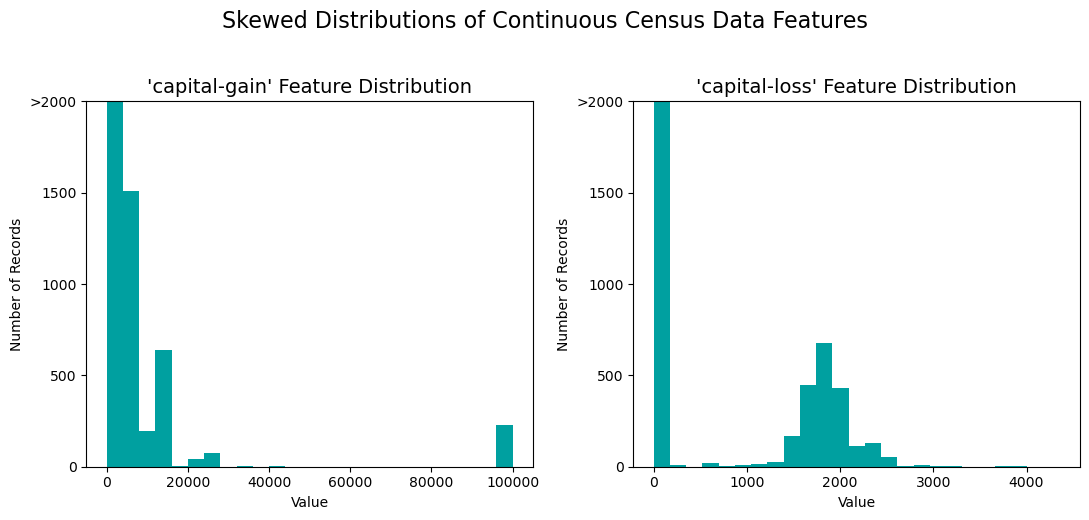

In [4]:
income_raw = data['income']
features_raw = data.drop('income', axis=1)

vs.distribution(data)

d:\Downloads\charityml\visuals.py:48: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


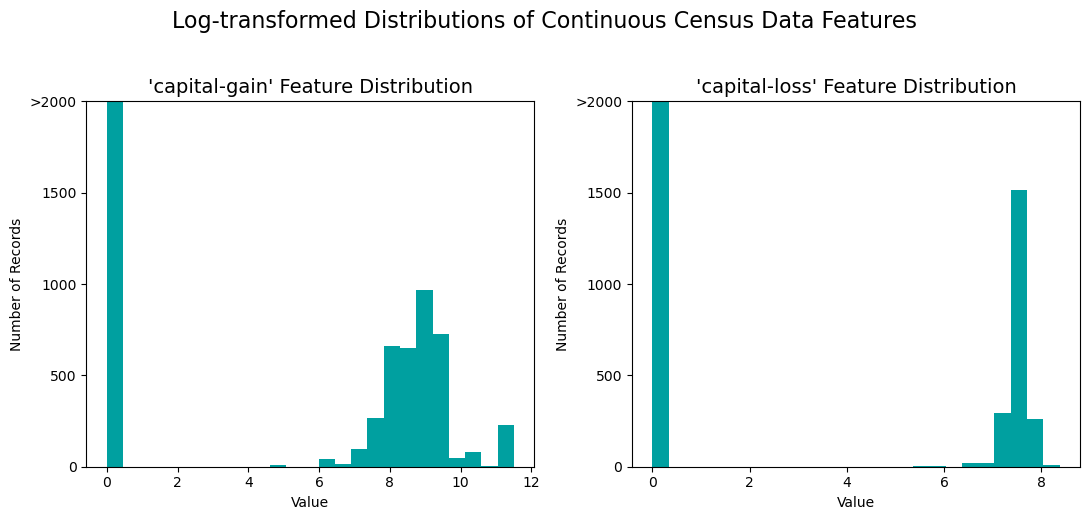

In [5]:
skewed = ['capital-gain', 'capital-loss']
features_raw[skewed] = data[skewed].apply(lambda x: np.log(x+1))

vs.distribution(features_raw, transformed=True)

In [6]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
numerical = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
features_raw[numerical] = scaler.fit_transform(data[numerical])

display(features_raw.head(n=1))

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,0.30137,State-gov,Bachelors,0.8,Never-married,Adm-clerical,Not-in-family,White,Male,0.02174,0.0,0.397959,United-States


In [7]:
features = pd.get_dummies(features_raw)

income = income_raw.apply(lambda x: 1 if x == ">50K" else 0)

encoded = list(features.columns)

print("{} total features after one-hot encoding.".format(len(encoded)))

103 total features after one-hot encoding.


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(features, income, test_size = 0.2, random_state = 0)

print("Training set has {} samples.".format(X_train.shape[0]))
print("Testing set has {} samples".format(X_test.shape[0]))

Training set has 36177 samples.
Testing set has 9045 samples


In [9]:
'''
TP = np.sum(income)
FP = income.count() - TP

TN = 0
FN = 0
'''

from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import fbeta_score

income_pred = income.apply(lambda x: 1)

TP = sum(map(lambda x, y: 1 if x==1 and y==1 else 0, income, income_pred))
FP = sum(map(lambda x, y: 1 if x==0 and y==1 else 0, income, income_pred))
FN = sum(map(lambda x, y: 1 if x==1 and y==0 else 0, income, income_pred))

accuracy = float(TP)/(TP+FP)

accuracy1 = accuracy_score(income, income_pred)
print('accuracy comparision', accuracy, accuracy1)

recall = float(TP)/(TP+FN)
recall1 = recall_score(income, income_pred)
print('recall comparision', recall, recall1)

beta = 0.5
fscore = (1+beta**2)*(accuracy*recall)/(beta**2*accuracy+recall)

fscore1 = fbeta_score(income, income_pred, beta=0.5)
print('fscore comparision', fscore, fscore1)

print("Naive Predictor: [Accuracy score: {:.4f}, F-score: {:.4f}]".format(accuracy, fscore))

accuracy comparision 0.2478439697492371 0.2478439697492371
recall comparision 1.0 1.0
fscore comparision 0.29172913543228385 0.29172913543228385
Naive Predictor: [Accuracy score: 0.2478, F-score: 0.2917]


Answer: I believe the most appropriate models to solve this problem are Gaussian Naive Bayes, Support Vector Machines(SVC), and the ensemble method Adaboost

The Multinomial Naive Bayes model has been widely used in the industry for text classification purposes. In particular for classifying and filtering spam emails based on the likelihood of certain words appearing on an spam email as compared to a non-spam email (ref: https://en.wikipedia.org/wiki/Naive_Bayes_classifier#Spam_filtering). The strength of this model lies in its simplicity inherited from the assumption that all features needed correctly to classifiy the data are "independent" from each other. This allows for the algorithm to be trained quickly and using less data. Furthermore, even when the underlying independence assumption is broken (i.e. when features have relationships between them), this algorithm still performs very well and is able to classify based on the maximum likelihood of a label given the set of features rather than on the actual probabilities of each feature. On the other hand, Naive Bayes's weakness is that if it encounters a previously unseen feature-label combination (on which it was never trained) it will incorrectly estimate likelyhood as 0 which can cause it to incorrectly classify the label. This particular model could be a good approach to solving the problem as we have  a large data set with few features.

Support Vector Machines (SVC) have been used in the industry successfully for handwritten digit identification to a level close to human classification error (ref: http://citeseerx.ist.psu.edu/viewdoc/download?doi=10.1.1.89.951&rep=rep1&type=pdfProne). This model is effective in high dimensional spaces and best suited for problems with complex domains where there are clear margins of seperation in the data. To correctly classify the data, this model is also capable of defining complex higher order seperation planes through custom kernels. One of the weakness of this model is that training can be time consuming on large datasets. Also, SVCs can perform poorly and overfit when the data is very noisy or overlaps too much. While training on our large current dataset may become an issue, the model could be still a good candidate as there seems to be some features in the data that can more clearly define the income level boundary. 